# 02 - Temporal analysis, 2015-2025

**Questions:** how has air pollution in Seoul changed from 2015 to 2025, how sure can we be of that trend, and how does it vary by season, weekday and hour? Ozone gets its own section, because it behaves unlike the other pollutants.

**Data:** the official hourly readings of the 25 urban stations built in notebook 07 (`air_daily_2015_2025.parquet`, `air_hourly_2015_2025.parquet`). Concentrations are right-skewed, so medians and percentiles are reported next to means.

**References:** Korean daily grades for PM2.5 (Bad above 35 ug/m3) and PM10 (Bad above 80); Korean annual standards (PM2.5 15, PM10 50 ug/m3, NO2 0.03 ppm); Korean ozone standards (0.06 ppm as an 8-hour mean, 0.1 ppm as a 1-hour mean); WHO 2021 guidelines (24-hour PM2.5 15, PM10 45 ug/m3; annual PM2.5 5, PM10 15).

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air import ozone, trend
from seoul_air.grades import GRADE_LABELS
from seoul_air.metrics import is_bad
from seoul_air.report import save_key_figures
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet")
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly_2015_2025.parquet")
GRADE_COLORS = {"Good": "#1f77b4", "Moderate": "#2ca02c", "Bad": "#f2a900", "Very bad": "#d62728"}
pollutants = list(config.POLLUTANTS)
# City-wide daily value: mean of the valid station daily means
city = daily.groupby("date")[pollutants].mean()
d = daily.assign(year=daily["date"].dt.year, month=daily["date"].dt.month)
print("Days:", len(city), "| from", city.index.min().date(), "to", city.index.max().date(),
      "| days with a city PM2.5 value:", int(city["pm25"].notna().sum()))

Days: 4018 | from 2015-01-01 to 2025-12-31 | days with a city PM2.5 value: 4018


## 2. Daily series

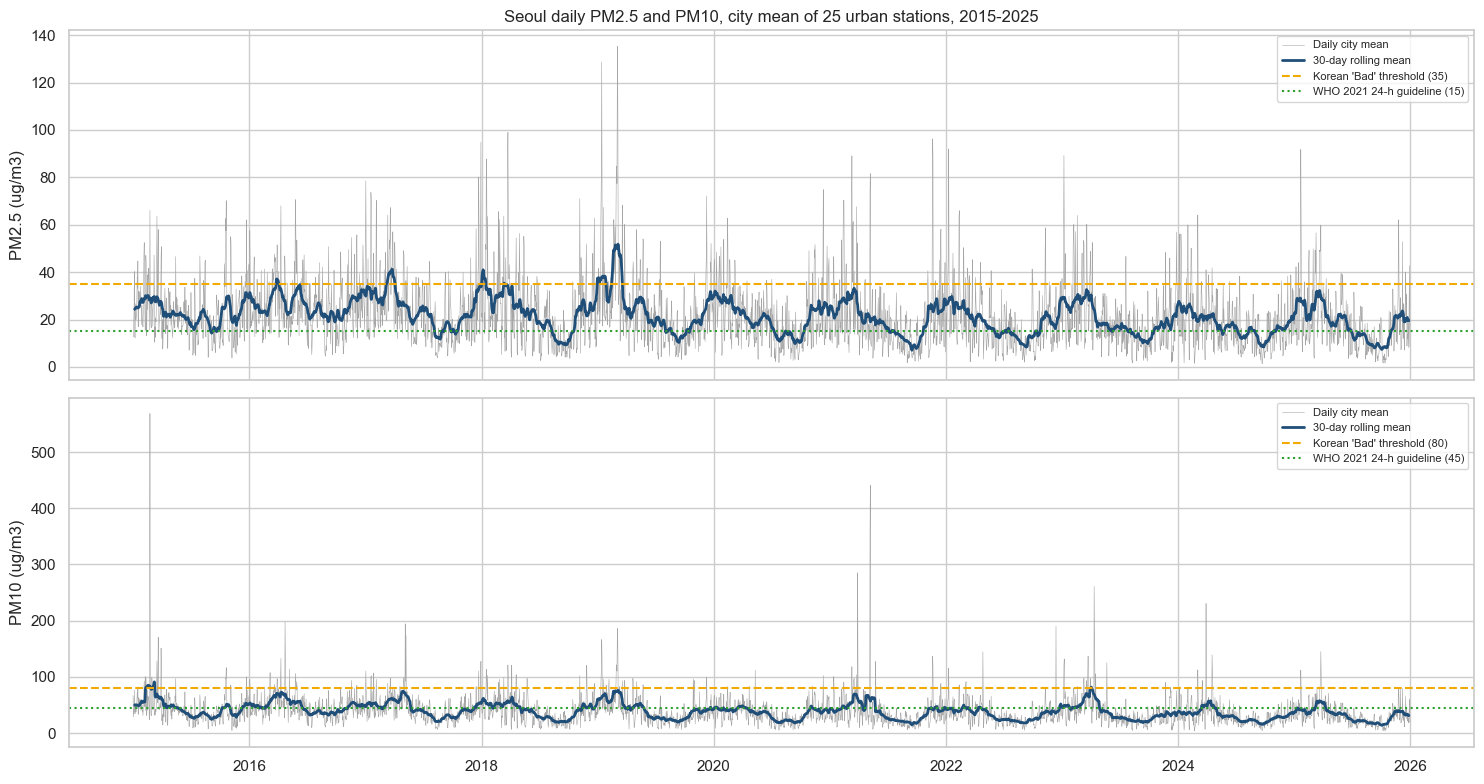

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, (col, bad, who) in zip(axes, [("pm25", 35, 15), ("pm10", 80, 45)]):
    ax.plot(city.index, city[col], lw=0.4, color="0.65", label="Daily city mean")
    rolling = city[col].rolling(30, center=True, min_periods=20).mean().where(city[col].notna())
    ax.plot(city.index, rolling, lw=2, color="#1f4e79", label="30-day rolling mean")
    ax.axhline(bad, color="#f2a900", ls="--", label=f"Korean 'Bad' threshold ({bad})")
    ax.axhline(who, color="#2ca02c", ls=":", label=f"WHO 2021 24-h guideline ({who})")
    ax.set_ylabel(f"{col.upper().replace('PM25', 'PM2.5')} (ug/m3)")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_title("Seoul daily PM2.5 and PM10, city mean of 25 urban stations, 2015-2025")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_daily_series.png", dpi=120)
plt.show()

## 3. Annual levels

In [4]:
valid = d.dropna(subset=["pm25"])
annual = d.groupby("year").agg(
    pm25_mean=("pm25", "mean"), pm25_median=("pm25", "median"),
    pm25_p90=("pm25", lambda s: s.quantile(0.9)),
    pm10_mean=("pm10", "mean"), no2_mean_ppm=("no2", "mean"), o3_mean_ppm=("o3", "mean"),
)
annual["pm25_bad_or_worse_days_%"] = valid.groupby("year")["pm25"].apply(lambda s: 100 * is_bad(s).mean())
annual["pm25_above_who_24h_%"] = valid.groupby("year")["pm25"].apply(lambda s: (s.round() > 15).mean() * 100)
annual.round({"pm25_mean": 1, "pm25_median": 1, "pm25_p90": 1, "pm10_mean": 1, "no2_mean_ppm": 4,
              "o3_mean_ppm": 4, "pm25_bad_or_worse_days_%": 1, "pm25_above_who_24h_%": 1})

,pm25_mean,pm25_median,pm25_p90,pm10_mean,no2_mean_ppm,o3_mean_ppm,pm25_bad_or_worse_days_%,pm25_above_who_24h_%
year,,,,,,,,
2015,23.2,21.1,39.0,45.5,0.0321,0.0224,13.4,73.4
2016,26.2,24.2,42.5,47.8,0.0314,0.0240,20.2,83.0
2017,24.6,21.6,42.9,43.7,0.0296,0.0249,17.8,71.2
2018,22.8,19.7,42.5,39.6,0.0282,0.0233,16.8,63.6
2019,25.0,20.5,46.0,42.1,0.0282,0.0250,17.6,68.7
2020,20.7,18.3,38.1,35.3,0.0238,0.0250,12.4,60.6
2021,19.8,16.2,36.1,38.3,0.0236,0.0278,10.5,53.3
2022,18.4,15.7,33.8,32.8,0.0209,0.0293,8.5,50.8
2023,19.7,16.7,35.5,37.9,0.0204,0.0310,10.0,55.7


**Interpretation.** The mean daily PM2.5 of a station fell from 23.2 ug/m3 in 2015 and 26.2 in 2016, the highest year, to 17.5 in 2024 and 18.5 in 2025, still above the Korean annual standard of 15 in every year. The share of station-days graded Bad or worse went from 20.2% in 2016 to 6.4% in 2024 (9.2% in 2025), and the share above the WHO 24-hour guideline from 83.0% to 50.3% in 2025. NO2 fell from 0.0321 to 0.0176 ppm, below the annual standard of 0.03 ppm from 2017 on, while the mean O3 rose from 0.0224 to 0.0332 ppm in 2024. These are means of station-day means, so they differ slightly from the hourly means of notebook 07 (23.29 in 2015).

## 4. Long-term trend with uncertainty

Year-to-year differences mix a trend with the weather of each year. To estimate the trend:

1. Monthly means of the city series (a month needs 20 valid days), minus the mean of their calendar month, remove the seasonal cycle.
2. The **Theil-Sen** slope (the median of all pairwise slopes) is robust to unusual months, such as the dust events of spring.
3. The 95% interval comes from a **moving-block bootstrap**: residuals are resampled in blocks of 12 consecutive months, because neighbouring months are not independent. An ordinary interval would be too narrow.

The slope is given in units per year and in percent of the mean level of 2015-2025. It describes the change over these years; it does not say why it happened, and weather is not adjusted for (that is the next step of the plan).

In [5]:
trends = pd.DataFrame({p: trend.trend(trend.monthly_means(city[p]), n_boot=2000) for p in pollutants}).T
trends[["months", "slope_per_year", "low_95", "high_95", "pct_per_year", "pct_low_95", "pct_high_95", "excludes_zero"]]

,months,slope_per_year,low_95,high_95,pct_per_year,pct_low_95,pct_high_95,excludes_zero
so2,132,-0.000284,-0.000332,-0.000235,-7.715999,-9.026808,-6.380054,True
no2,132,-0.00153,-0.001649,-0.001419,-6.129002,-6.60614,-5.683065,True
co,132,-0.012431,-0.014841,-0.010008,-2.614683,-3.121559,-2.104979,True
o3,132,0.001043,0.00084,0.001251,3.849527,3.100366,4.615535,True
pm10,132,-1.436425,-1.806981,-1.046572,-3.715552,-4.674057,-2.707132,True
pm25,132,-0.758139,-0.97489,-0.541323,-3.532122,-4.54195,-2.521989,True


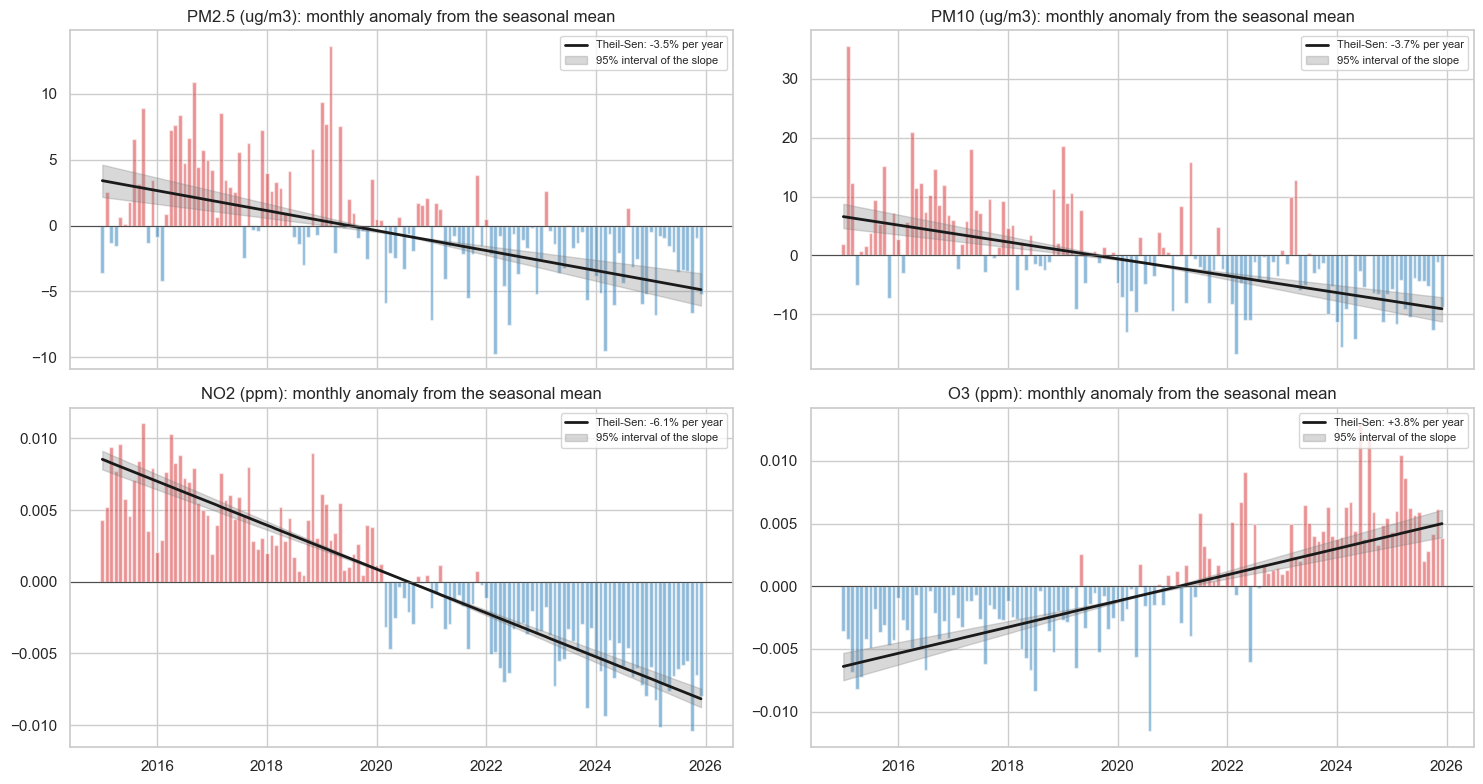

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, (p, label) in zip(axes.ravel(), [("pm25", "PM2.5 (ug/m3)"), ("pm10", "PM10 (ug/m3)"),
                                         ("no2", "NO2 (ppm)"), ("o3", "O3 (ppm)")]):
    monthly = trend.monthly_means(city[p])
    anomalies = trend.deseasonalise(monthly).dropna()
    t = trend.years_since_start(anomalies.index)
    slope, intercept = trend.theil_sen(t, anomalies.to_numpy())
    slopes = trend.block_bootstrap_slopes(t, anomalies.to_numpy(), n_boot=500, seed=1)
    x = anomalies.index.to_timestamp()
    centre = t.mean()
    low, high = np.percentile(slopes, [2.5, 97.5])
    ax.bar(x, anomalies, width=25, color=np.where(anomalies > 0, "#d62728", "#1f77b4"), alpha=0.5)
    ax.plot(x, intercept + slope * t, color="k", lw=2, label=f"Theil-Sen: {100 * slope / monthly.mean():+.1f}% per year")
    base = intercept + slope * centre
    ax.fill_between(x, base + low * (t - centre), base + high * (t - centre), color="0.5", alpha=0.3,
                    label="95% interval of the slope")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(f"{label}: monthly anomaly from the seasonal mean")
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_long_term_trend.png", dpi=120)
plt.show()

In [7]:
# The same estimate for each station (PM2.5): is the decline shared across Seoul?
station_trends = []
for district, rows in daily.groupby("district"):
    result = trend.trend(trend.monthly_means(rows.set_index("date")["pm25"]), n_boot=500)
    station_trends.append({"district": district, **result})
station_trends = pd.DataFrame(station_trends).set_index("district").sort_values("pct_per_year")
print(f"Stations with a decline whose interval excludes zero: {int((station_trends['high_95'] < 0).sum())} of {len(station_trends)}")
print(f"Station slopes: from {station_trends['pct_per_year'].min():.1f}% to {station_trends['pct_per_year'].max():.1f}% per year")
station_trends[["pct_per_year", "pct_low_95", "pct_high_95"]].round(2).T

Stations with a decline whose interval excludes zero: 25 of 25
Station slopes: from -5.0% to -2.5% per year


district,Gwanak-gu,Mapo-gu,Eunpyeong-gu,Seongdong-gu,Gwangjin-gu,Dobong-gu,Gangseo-gu,Seodaemun-gu,Yongsan-gu,Seongbuk-gu,...,Dongjak-gu,Songpa-gu,Yangcheon-gu,Dongdaemun-gu,Jungnang-gu,Jung-gu,Gangbuk-gu,Gangdong-gu,Seocho-gu,Nowon-gu
pct_per_year,-4.96,-4.43,-4.18,-4.17,-4.14,-4.02,-3.72,-3.69,-3.67,-3.57,...,-3.21,-3.19,-3.14,-3.09,-3.09,-3.06,-3.05,-2.91,-2.87,-2.47
pct_low_95,-6.61,-5.83,-5.58,-5.29,-5.59,-5.10,-4.67,-4.89,-5.00,-5.08,...,-3.88,-4.28,-4.14,-4.21,-4.78,-4.05,-4.27,-4.22,-3.89,-3.58
pct_high_95,-3.45,-2.96,-2.79,-2.79,-2.66,-2.86,-2.77,-2.25,-2.37,-2.18,...,-2.52,-2.13,-2.03,-2.04,-1.36,-2.17,-1.82,-1.37,-1.76,-1.30


**Interpretation.** Every pollutant has a trend whose 95% interval excludes zero. PM2.5 falls by 3.53% of its mean level per year (interval 2.52% to 4.54%), about 0.76 ug/m3 a year; PM10 by 3.72%; CO by 2.61%; NO2 by 6.13% and SO2 by 7.72%, the fastest. **Ozone rises by 3.85% a year** (interval 3.10% to 4.62%), the only pollutant moving the other way. The PM2.5 decline is shared across the city: all 25 stations decline, with slopes from 2.5% to 5.0% a year, and every station's interval excludes zero. These slopes describe 2015-2025; they include years with unusual weather and the COVID-19 period, and the weather is not adjusted for, so they do not show what caused the decline. The ozone trend is consistent with the fall of NO2, which consumes ozone near the ground, but this dataset cannot test that explanation.

## 5. Seasonality

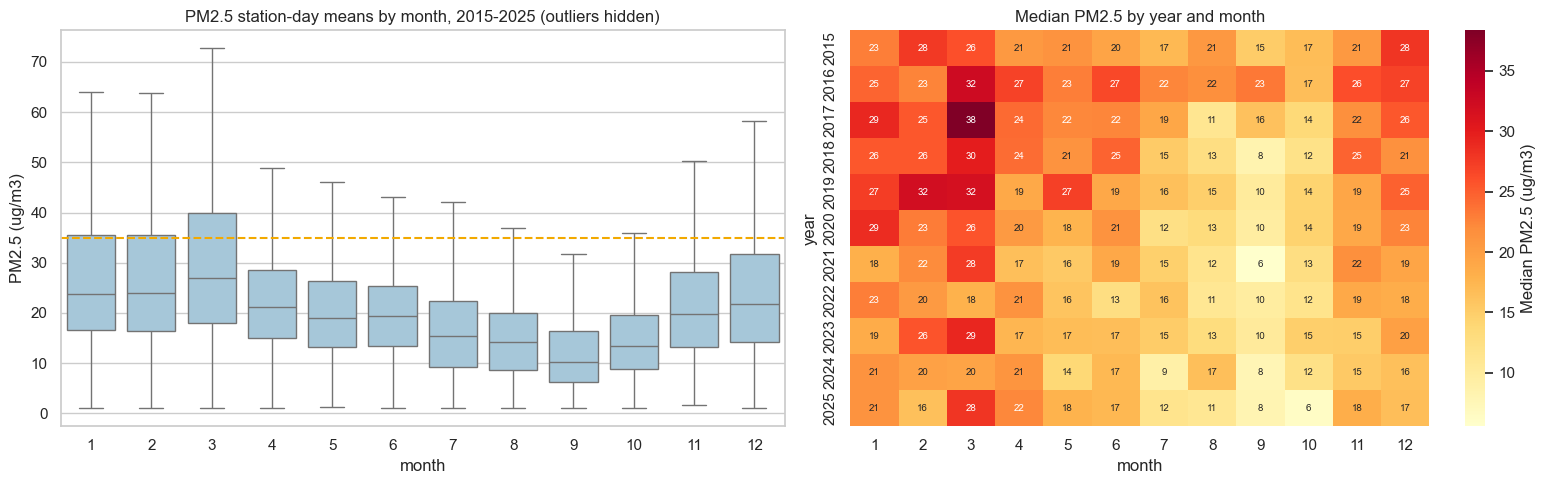

month          1     2     3     4     5     6     7     8     9     10    11    12
pm25_median  23.7  24.0  27.0  21.2  19.0  19.3  15.3  14.2  10.2  13.5  19.7  21.8


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=d, x="month", y="pm25", color="#9ecae1", showfliers=False, ax=axes[0])
axes[0].axhline(35, color="#f2a900", ls="--")
axes[0].set_title("PM2.5 station-day means by month, 2015-2025 (outliers hidden)")
axes[0].set_ylabel("PM2.5 (ug/m3)")
by_year_month = d.groupby(["year", "month"])["pm25"].median().unstack()
sns.heatmap(by_year_month, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Median PM2.5 (ug/m3)"}, ax=axes[1])
axes[1].set_title("Median PM2.5 by year and month")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_seasonality.png", dpi=120)
plt.show()
month_median = d.groupby("month")["pm25"].median()
print(month_median.round(1).to_frame("pm25_median").T.to_string())

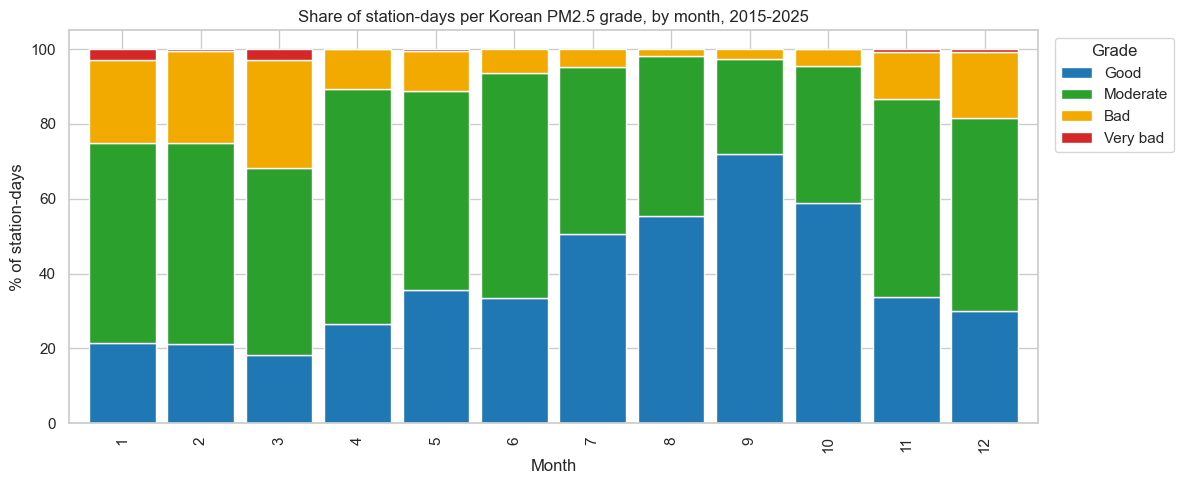

grade,Good,Moderate,Bad,Very bad
month,,,,
1,21.4,53.5,22.4,2.8
2,21.3,53.8,24.5,0.5
3,18.2,49.9,29.0,2.9
4,26.6,62.7,10.6,0.1
5,35.5,53.3,10.7,0.4
6,33.4,60.3,6.3,0.0
7,50.7,44.5,4.9,0.0
8,55.5,42.6,1.9,0.0
9,71.9,25.4,2.7,0.0


In [9]:
share = (valid.assign(grade=valid["pm25_grade"])
          .groupby("month")["grade"].value_counts(normalize=True)
          .mul(100).unstack()[GRADE_LABELS])
ax = share.plot(kind="bar", stacked=True, figsize=(12, 5), color=[GRADE_COLORS[g] for g in GRADE_LABELS], width=0.85)
ax.set_title("Share of station-days per Korean PM2.5 grade, by month, 2015-2025")
ax.set_ylabel("% of station-days")
ax.set_xlabel("Month")
ax.legend(title="Grade", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(config.FIGURES / "02_grade_share_by_month.png", dpi=120)
plt.show()
bad_share = share["Bad"] + share["Very bad"]
share.round(1)

**Interpretation.** The seasonal cycle is unchanged over the period: the median station-day PM2.5 is highest in March (27.0 ug/m3) and lowest in September (10.2). In March 31.9% of station-days are Bad or worse, against 1.9% in August. The heat map shows the same months standing out every year at a lower level in the later years.

## 6. Weekday and hour of day

In [10]:
weekday = city.groupby(city.index.weekday)[["pm25", "pm10", "no2"]].median()
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday.round(3)

,pm25,pm10,no2
Mon,17.619,32.990,0.023
Tue,18.435,32.899,0.024
Wed,19.234,34.668,0.024
Thu,18.974,34.903,0.024
Fri,19.469,34.663,0.024
Sat,19.175,34.011,0.022
Sun,18.079,31.137,0.019


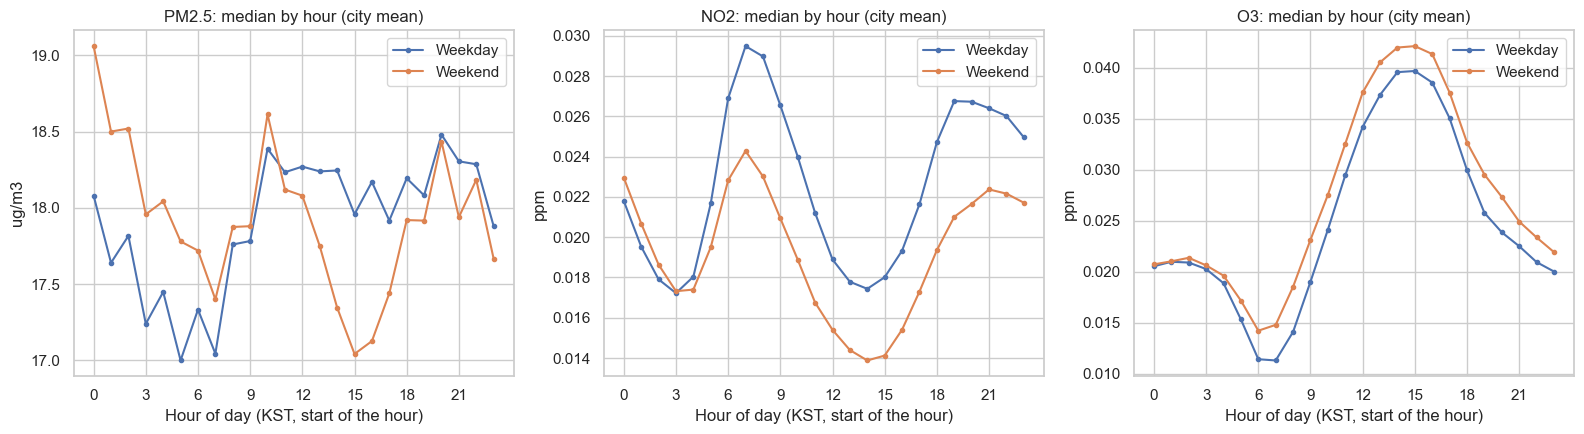

pm25: weekday peak at 20h (18.480), minimum at 5h (17.000)
no2: weekday peak at 7h (0.029), minimum at 3h (0.017)
o3: weekday peak at 15h (0.040), minimum at 7h (0.011)


In [11]:
h = hourly.groupby("datetime")[["pm25", "no2", "o3"]].mean()
h["hour"] = h.index.hour
h["day_type"] = np.where(h.index.weekday >= 5, "Weekend", "Weekday")
profile = h.groupby(["day_type", "hour"])[["pm25", "no2", "o3"]].median()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, unit in zip(axes, ["pm25", "no2", "o3"], ["ug/m3", "ppm", "ppm"]):
    for day_type, grp in profile[col].groupby(level=0):
        ax.plot(grp.index.get_level_values(1), grp.values, marker="o", ms=3, label=day_type)
    ax.set_title(f"{col.upper().replace('PM25', 'PM2.5')}: median by hour (city mean)")
    ax.set_xlabel("Hour of day (KST, start of the hour)")
    ax.set_ylabel(unit)
    ax.set_xticks(range(0, 24, 3))
    ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "02_hourly_profile.png", dpi=120)
plt.show()
for col in ["pm25", "no2", "o3"]:
    wk = profile.loc["Weekday", col]
    print(f"{col}: weekday peak at {wk.idxmax()}h ({wk.max():.3f}), minimum at {wk.idxmin()}h ({wk.min():.3f})")

**Interpretation.** PM2.5 has no strong weekly or daily cycle: its median stays between 17.6 and 19.5 ug/m3 across weekdays and between 17.0 and 18.5 across the hours of a weekday. NO2, a gas commonly linked to road traffic, falls to 0.019 ppm on Sundays against 0.022 to 0.024 on other days and peaks at 7h (07:00-08:00), an hour that matches the morning rush. O3 peaks at 15h (0.040 ppm) and is lowest at 7h (0.011), a daily shape consistent with ozone forming in sunlight. Hours are KST and mark the start of each hourly average.

## 7. Ozone

Ozone is not emitted directly: it forms in sunlight from other pollutants, so it peaks in the afternoon and in the warm season, when particulate matter is low. The Korean standard is set on the **highest 8-hour mean of the day** (0.06 ppm) and on the 1-hour mean (0.1 ppm); an ozone warning starts at 0.12 ppm in one hour. The 8-hour means below end at each hour of the day and need 6 valid hours.

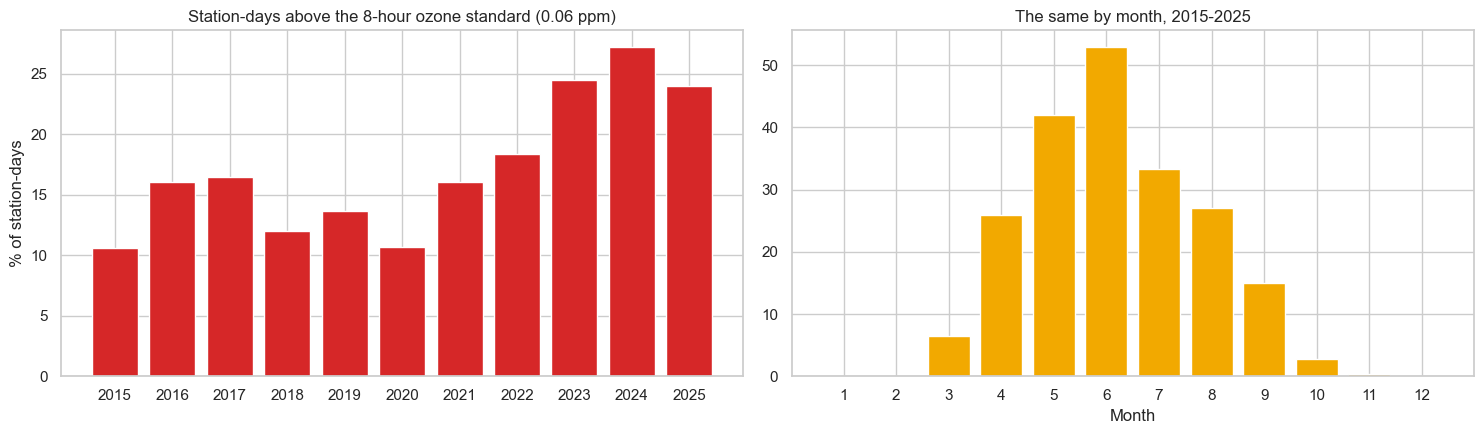

Months with the most exceedances: {6: 52.9, 5: 42.0, 7: 33.3}


,station_days,above_8h_standard_pct,above_1h_standard_pct,warning_level_station_days,median_max_8h_ppm
year,,,,,
2015,9022,10.607,0.744,8,0.034
2016,8991,16.072,3.377,71,0.035
2017,9081,16.507,2.764,79,0.037
2018,8973,11.980,3.393,136,0.035
2019,8945,13.628,2.280,68,0.037
2020,9137,10.649,2.593,64,0.035
2021,9097,16.082,2.822,87,0.040
2022,9068,18.416,3.272,112,0.040
2023,9063,24.539,4.193,115,0.044


In [12]:
by_station = hourly.set_index("datetime").groupby("station_code")["o3"]
max_8h = by_station.apply(ozone.daily_max_8h).rename("o3_max_8h").reset_index()
max_1h = by_station.apply(ozone.daily_max_1h).rename("o3_max_1h").reset_index()
o3_days = max_8h.merge(max_1h, on=["station_code", "datetime"]).rename(columns={"datetime": "date"})
o3_days["year"] = o3_days["date"].dt.year
o3_days["month"] = o3_days["date"].dt.month
o3_year = o3_days.groupby("year").agg(
    station_days=("o3_max_8h", "count"),
    above_8h_standard_pct=("o3_max_8h", lambda s: 100 * (s.dropna() > ozone.STANDARD_8H_PPM).mean()),
    above_1h_standard_pct=("o3_max_1h", lambda s: 100 * (s.dropna() > ozone.STANDARD_1H_PPM).mean()),
    warning_level_station_days=("o3_max_1h", lambda s: int((s >= ozone.WARNING_1H_PPM).sum())),
    median_max_8h_ppm=("o3_max_8h", "median"),
)
o3_month = o3_days.groupby("month")["o3_max_8h"].apply(lambda s: 100 * (s.dropna() > ozone.STANDARD_8H_PPM).mean())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(o3_year.index, o3_year["above_8h_standard_pct"], color="#d62728")
axes[0].set_title("Station-days above the 8-hour ozone standard (0.06 ppm)")
axes[0].set_ylabel("% of station-days")
axes[0].set_xticks(o3_year.index)
axes[1].bar(o3_month.index, o3_month, color="#f2a900")
axes[1].set_title("The same by month, 2015-2025")
axes[1].set_xlabel("Month")
axes[1].set_xticks(range(1, 13))
fig.tight_layout()
fig.savefig(config.FIGURES / "02_ozone.png", dpi=120)
plt.show()
print("Months with the most exceedances:", o3_month.sort_values(ascending=False).head(3).round(1).to_dict())
o3_year.round(3)

**Interpretation.** Exceedances of the ozone standard are rising. The share of station-days whose highest 8-hour mean is above 0.06 ppm went from 10.6% in 2015 to 27.2% in 2024 (24.0% in 2025); station-days above the 1-hour standard from 0.744% to 8.345% in 2024; and station-days reaching the warning level (0.12 ppm in one hour) from 8 in 2015 to 298 in 2024 and 153 in 2025. Exceedances concentrate in June (52.9% of station-days), May (42.0%) and July (33.3%). The median of the daily highest 8-hour mean rose from 0.034 to 0.045 ppm in 2024. While particulate matter improves, ozone is becoming the main air quality problem of the warm season.

## 8. Key figures

In [13]:
save_key_figures("02", {
    "pm25_median_by_month": month_median.to_dict(),
    "bad_or_worse_pct_by_month": bad_share.to_dict(),
    "pm25_mean_by_year": annual["pm25_mean"].to_dict(),
    "trend": trends[["slope_per_year", "low_95", "high_95", "pct_per_year", "pct_low_95", "pct_high_95"]].astype(float).to_dict(orient="index"),
    "stations_with_significant_pm25_decline": int((station_trends["high_95"] < 0).sum()),
    "o3_above_8h_pct_by_year": o3_year["above_8h_standard_pct"].to_dict(),
})
print((config.METRICS / "02_key_figures.json").read_text())

{
  "bad_or_worse_pct_by_month": {
    "1": 25.148632580261594,
    "10": 4.390659207005594,
    "11": 13.258092521394023,
    "12": 18.44903811685984,
    "2": 24.96413199426112,
    "3": 31.905730350520393,
    "4": 10.67624473619024,
    "5": 11.132232386836165,
    "6": 6.292245299250338,
    "7": 4.865188735769922,
    "8": 1.897510273144791,
    "9": 2.662796567390207
  },
  "o3_above_8h_pct_by_year": {
    "2015": 10.607404123254268,
    "2016": 16.071627182738293,
    "2017": 16.506992621957934,
    "2018": 11.980385601248189,
    "2019": 13.627724986025713,
    "2020": 10.649009521724855,
    "2021": 16.08222490931076,
    "2022": 18.416409351565946,
    "2023": 24.53933576078561,
    "2024": 27.241795631654043,
    "2025": 24.01235930258221
  },
  "pm25_mean_by_year": {
    "2015": 23.245396721071195,
    "2016": 26.184279292632883,
    "2017": 24.568303187115703,
    "2018": 22.793366983093325,
    "2019": 24.95180712467575,
    "2020": 20.70944499323209,
    "2021": 19.8484